In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re

In [2]:
def get_atomic_numers(w_uc,  N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc ):
    #calculate number of atom in the whole config, of every species and per surface.

    #determine the size factor "f": f_small=3x3=9; f_big=6x6=36;   f_full_coverage=4x4=16: 
    
    print(f"Water/uc/Surface = {w_uc}")
    if w_uc in (1,2,3,4):
        f=9
    elif w_uc in (5,6,7,8):
        f=36
    elif w_uc==68:
        f=16
    print(f"size_factor = {f}")
    


    
    #species
    N_water=w_uc*f*2         #*2 surfaces
    N_H=N_water*2             
    N_O_mag=N_O_mag_uc*f
    N_O=N_O_mag+N_water
    N_Fe=N_Fe_mag_uc*f
    N_atom=N_H+N_O+N_Fe

    #surface
    N_OS=N_OS_uc*f
    N_FeS=N_FeS_uc*f
    N_FeS2= N_FeS2_uc*f

    

    print(f"N_water = {N_water}")
    print(f"N_H = {N_H}")
    print(f"N_O = {N_O}")
    print(f"N_Fe = {N_Fe}")
    print(f"N_atom = {N_atom}")
    print(f"N_O surface = {N_OS}")
    print(f"N_Fe surface_1&2 = {N_FeS},  {N_FeS2}")

    return(  N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 )

In [ ]:
def pre_parsing_get_initial_lines(trj):
     
    real_timestep=[]
    line_count=0
    initial_lines=[]
    # Read the trj file. set the header and the pattern of starting of a config
    with open(trj, 'r') as file:
        pattern= r"TIMESTEP"
        
        for line in file:
            line_count+=1

            if  re.search(pattern, line):
                initial_lines.append(line_count)
            if line_count== initial_lines[-1]+1:
                real_timestep.append(line)
    return initial_lines, real_timestep
       

In [3]:
def trj_analysis(trj , N_water , N_H, N_O, N_Fe ,N_OS, N_FeS, N_FeS2 ):
     
    H_u=[]
    H_d=[]
    O_u=[]
    O_d=[]
    OS_u=[]
    OS_d=[]
    FeS_u=[]
    FeS2_u=[]
    FeS_d=[]
    FeS2_d=[]

    tmp_H_u=[]
    tmp_H_d=[]
    tmp_O_u=[]
    tmp_O_d=[]
    tmp_OS_u=[]
    tmp_OS_d=[]
    tmp_FeS_u=[]
    tmp_FeS2_u=[]
    tmp_FeS_d=[]
    tmp_FeS2_d=[]



    # Read the trj file. set the header and the pattern of starting of a config
    with open(trj, 'r') as file:
        pattern= r"TIMESTEP"
        header=9
        line_count=0
        for line in file:
            line_count+=1

            if  re.search(pattern, line):
                
                line_count=0    
                #appending coordinates of a given config
                if tmp_H_u !=  []:
                    H_u.append(tmp_H_u)
                    H_d.append(tmp_H_d)

                    O_u.append(tmp_O_u)
                    OS_u.append(tmp_OS_u)
                    O_d.append(tmp_O_d)
                    OS_d.append(tmp_OS_d)

                    FeS_u.append(tmp_FeS_u)
                    FeS2_u.append(tmp_FeS2_u)
                    FeS2_d.append(tmp_FeS2_d)
                    FeS_d.append(tmp_FeS_d)
                

                tmp_H_u=[]
                tmp_H_d=[]
                tmp_O_u=[]
                tmp_O_d=[]
                tmp_OS_u=[]
                tmp_OS_d=[]
                tmp_FeS_u=[]
                tmp_FeS2_u=[]
                tmp_FeS_d=[]
                tmp_FeS2_d=[]
                
            if line_count<header:
                continue
            #Hydrogen up and down
            elif line_count<header+N_H/2:
                split_line=line.split()
                tmp_H_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
             
            elif line_count<header+N_H:
                split_line=line.split()
                tmp_H_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])

            #Oxygen water up, surface up, (skip bulk) surface down and water down  
            elif line_count<header+N_H+N_water/2:
                split_line=line.split()
                tmp_O_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+N_water/2+N_OS:
                split_line=line.split()
                tmp_OS_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+ N_O -N_water/2 -N_OS: 
                continue 
            elif line_count<header+N_H+ N_O -N_water/2 :
                split_line=line.split()
                tmp_OS_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+ N_O :
                split_line=line.split()
                tmp_O_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            #Fe surface up, second layer up, (skip bulk); down second layer down
            elif line_count<header+N_H+N_O+N_FeS:
                split_line=line.split()
                tmp_FeS_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+N_O+N_FeS+N_FeS2:
                split_line=line.split()
                tmp_FeS2_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+N_O+N_Fe - N_FeS-N_FeS2 :
                continue
            elif line_count<header+N_H+N_O+N_Fe -N_FeS:
                split_line=line.split()
                tmp_FeS2_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            elif line_count<header+N_H+N_O+N_Fe:
                split_line=line.split()
                tmp_FeS_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
          
                
    #appending coordinates of lastconfig
    H_u.append(tmp_H_u)
    H_d.append(tmp_H_d)

    O_u.append(tmp_O_u)
    OS_u.append(tmp_OS_u)
    O_d.append(tmp_O_d)
    OS_d.append(tmp_OS_d)

    FeS_u.append(tmp_FeS_u)
    FeS2_u.append(tmp_FeS2_u)
    FeS2_d.append(tmp_FeS2_d)
    FeS_d.append(tmp_FeS_d)

    print(f"trj lenght={len(H_u)}")
    return np.array(H_u),np.array(H_d),np.array(O_u),np.array(OS_u),np.array(OS_d),np.array(O_d),np.array(FeS_u),np.array(FeS2_u),np.array(FeS2_d),np.array(FeS_d)
       

In [4]:



# FIRST PAPER
# magnetite 1 u.c. data
#8.396 0.0 0.0
#0.0 8.396 0.0
#0.0 0.0 34.7337          
#O Fe
#72 50

#Full Coverage L_z = 71.4784

#number of O/Fe atom per uc
N_O_mag_uc=72               #second paper  N_O_mag_uc=64    
N_Fe_mag_uc=50              #second paper  N_Fe_mag_uc=44
#box lenght unit cell!
L_x_uc=8.3617      #second paper same (8.396)
L_y_uc=8.3617

#SCV structure (1uc)
N_OS_uc=8    # number oxygen in first outer layer/uc
N_FeS_uc=4   # number of iron in first outer layer/uc
N_FeS2_uc=3  # number of iron  second/outer layer/uc

#water per u.c. per surface
w_uc=98.5                                  #second paper full= 68
n_replica=4                              #if it is replicated 2x2 n_replica=2        
f=n_replica**2
#boundaries #only for full coverage
z_interval_u=[42.5, 41.1, 40.1]     
z_interval_d=[26.29, 27.45, 28.5]   



L_x=L_x_uc*n_replica
L_y=L_y_uc*n_replica
#L_z = 71.4784
L_z=103.014 
diag_lenght=np.sqrt(L_x**2+ L_y**2)


#oct/tet
control_u='u'
control_d='d'  








In [35]:

#trj should be ordered from z and clustered by atom
trj="./water_1_uc/run_1/tmp"      #path to trj
w_uc=1               #water per uc per surface: between 1 and 8 or 68==full_coverage (consistent with trj loaded)

#tot number of H, O, Fe, number of O in the magnetite surface and Fe in the 2 outermost layers 
N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 = get_atomic_numers(w_uc, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc)




Water/uc/Surface = 1
size_factor = 9
N_water = 18
N_H = 36
N_O = 594
N_Fe = 396
N_atom = 1026
N_O surface = 72
N_Fe surface_1&2 = 36,  27


In [36]:
#Hydrogen up, down; Oxygen water up, surface up, surface down, water down, Fe surface up, second layer up, second layer down , surface down
H_u, H_d, O_u, OS_u, OS_d, O_d, FeS_u, FeS2_u, FeS2_d, FeS_d=trj_analysis(trj, N_water,  N_H, N_O, N_Fe,  N_OS, N_FeS, N_FeS2  )


#numberof atoms: 1026 1080 1134 1188 4968 5184 5616 8256

trj lenght=192


In [37]:
type_name =["H_u", "H_d", "O_u", "OS_u", "OS_d", "O_d", "FeS_u", "FeS2_u", "FeS2_d", "FeS_d"]
trj_all=[H_u, H_d, O_u, OS_u, OS_d, O_d, FeS_u, FeS2_u, FeS2_d, FeS_d]

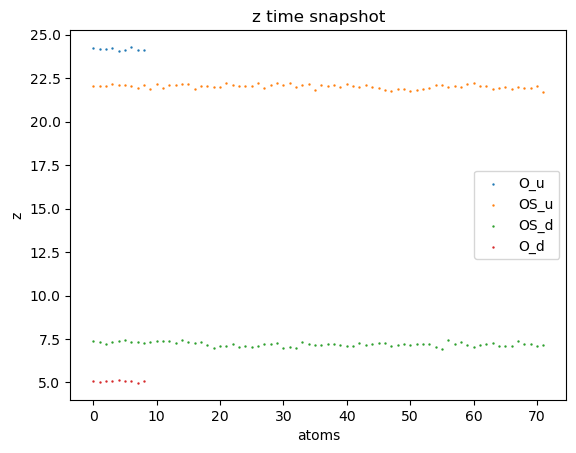

In [38]:
for i, element in enumerate(trj_all[2:6]):
    plt.scatter(np.arange(len(element[0][:,2])), element[0][:,2], label = type_name[i+2] , s =0.5)
    plt.title("z time snapshot")
    plt.ylabel("z")
    plt.xlabel("atoms")
    plt.legend()
    

In [41]:
np.mean(OS_d[:,2])



9.418705538194445

16.36

In [ ]:
16.375